Questão 1


ITUB4    0.198192
MGLU3    0.274458
MULT3    0.136353
PETR4    0.360625
TOTS3    0.238459
dtype: float64
          ITUB4     MGLU3     MULT3     PETR4     TOTS3
ITUB4  0.080451  0.066092  0.056679  0.056605  0.036627
MGLU3  0.066092  0.419392  0.101631  0.068317  0.098779
MULT3  0.056679  0.101631  0.122009  0.058859  0.059662
PETR4  0.056605  0.068317  0.058859  0.164464  0.040817
TOTS3  0.036627  0.098779  0.059662  0.040817  0.142482


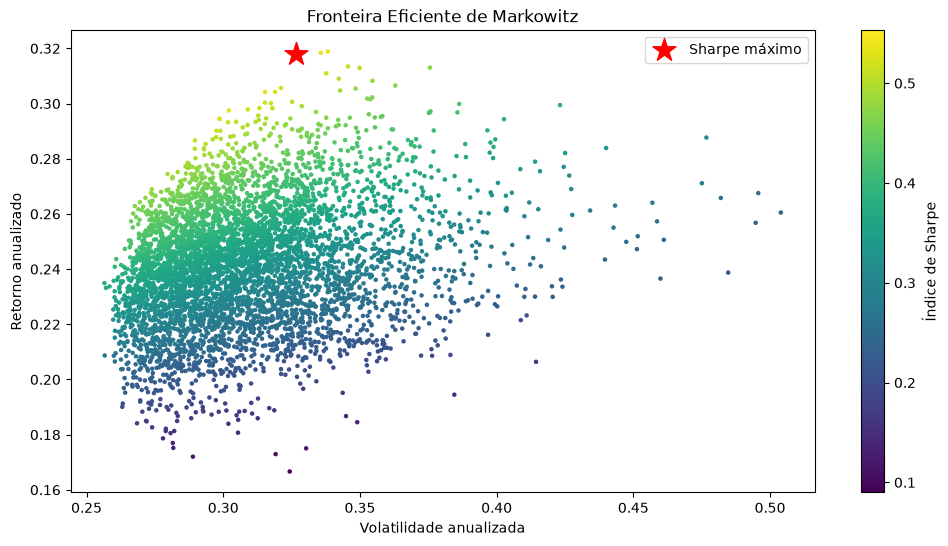

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#Carregando as bases e dados necessários para o gráfico
cotacoes = pd.read_excel('economatica(3).xlsx', index_col=0, header=3, na_values='-')
nomes_novos = []
for cotacao in cotacoes.columns:
    nomes_novos.append(cotacao.split("\n")[-1])
cotacoes.columns = nomes_novos
cotacoes = cotacoes.dropna()
acoes = ['ITUB4', 'MGLU3', 'MULT3', 'PETR4', 'TOTS3']
cotacoes = cotacoes[acoes]
retorno_simples = cotacoes.pct_change().dropna()
retorno_medio_anualizado = retorno_simples.mean() * 252
covariancia_anualizada = retorno_simples.cov() * 252
selic = 0.1375
#Simulação de 5000 carteiras aleatórias
sharpes = []
lista_pesos = []
volatilidades = []
retornos = []
for x in range(0, 5000):
    peso = np.random.random(5)
    pesos = peso / np.sum(peso)
    lista_pesos.append(peso)
    retorno_portfolio = pesos @ retorno_medio_anualizado
    retornos.append(retorno_portfolio)
    volatilidade_portfolio = np.sqrt(pesos @ covariancia_anualizada @ pesos)
    volatilidades.append(volatilidade_portfolio)
    sharpe = (retorno_portfolio - selic) / volatilidade_portfolio
    sharpes.append(sharpe)

indice = np.argmax(sharpes)
pesos_max_sharpe = pd.Series(lista_pesos[indice], index=acoes)

print(retorno_medio_anualizado)
print(covariancia_anualizada)

plt.figure(figsize=(12, 6))
plt.scatter(volatilidades, retornos, c=sharpes, s=5)
plt.colorbar(label='Índice de Sharpe')
plt.scatter(volatilidades[indice], retornos[indice], color='red', marker='*', s=300, label='Sharpe máximo')
plt.title('Fronteira Eficiente de Markowitz')
plt.xlabel('Volatilidade anualizada')
plt.ylabel('Retorno anualizado')
plt.legend()
plt.show()
